# PCD Assignment 02: Image Enhancement Based on Filtering
**Nama:** Nabila Aisy Shifa  
**NIM:** 25/560484/PA/23619
**Kelas:** PCD KOM

Tugas ini mengimplementasikan image enhancement menggunakan dua pendekatan filtering:
1. **Spatial Domain Filtering**: mean filter, median filter, Gaussian filter, Laplacian sharpening
2. **Frequency Domain Filtering**: Ideal, Butterworth, dan Gaussian Low-Pass & High-Pass Filter


In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data, img_as_float, img_as_ubyte
from skimage.util import random_noise
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import mean_squared_error as mse

plt.rcParams['figure.figsize'] = (14, 6)
np.random.seed(42)

## 1. Menyiapkan Citra Dasar (Ground Truth)



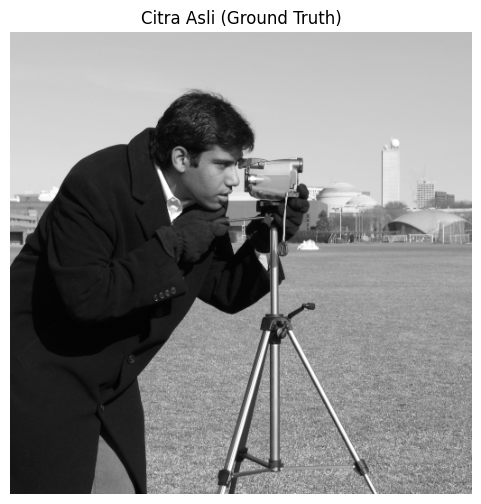

In [ ]:
original = img_as_ubyte(data.camera())

plt.imshow(original, cmap='gray')
plt.title('Citra Asli (Ground Truth)')
plt.axis('off')
plt.show()

## 2. Membuat Citra Terdegradasi

- **Blur**: konvolusi dengan Gaussian kernel besar (mensimulasikan defocus blur)
- **Salt & Pepper noise**: derau impulsif
- **Gaussian noise**: derau acak berdistribusi normal

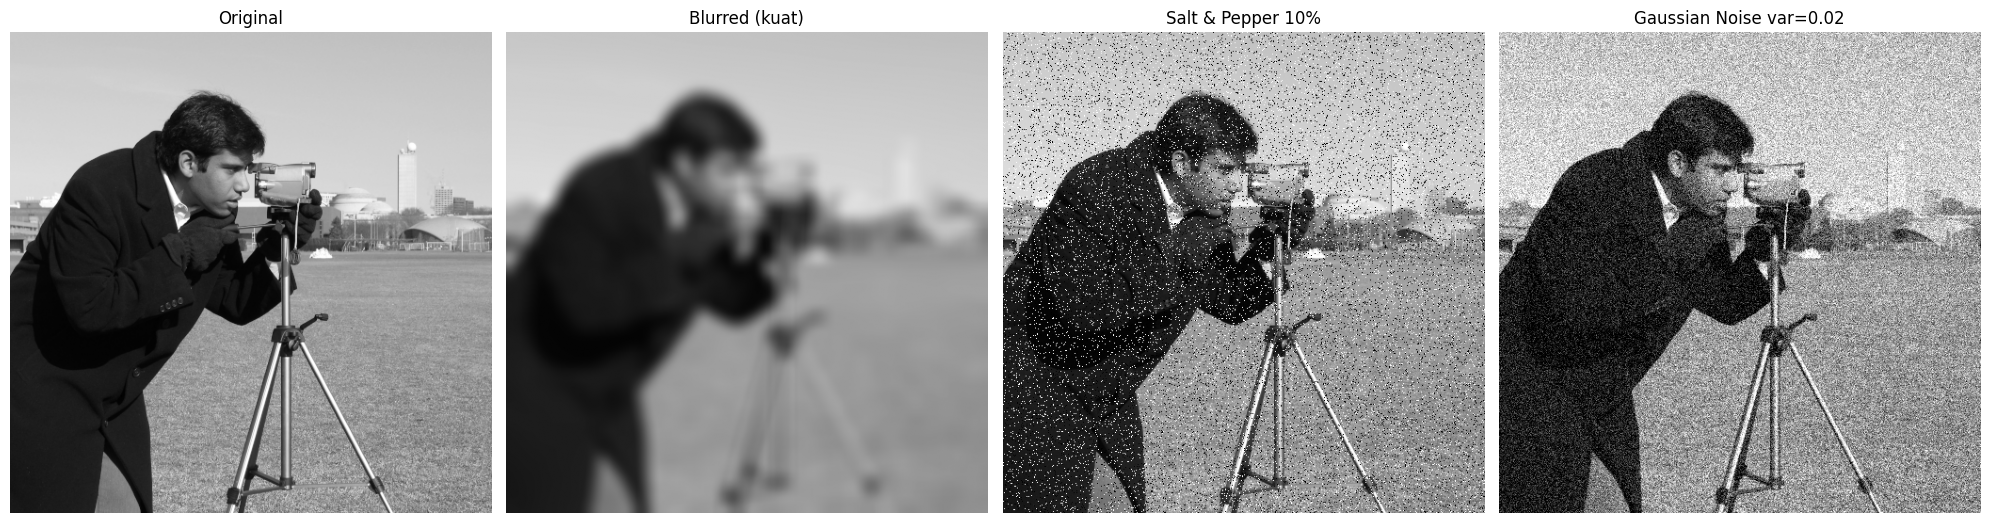

In [ ]:
# blur
blurred = cv2.GaussianBlur(original, (25, 25), sigmaX=8)

# salt & Pepper
sp_noisy = img_as_ubyte(random_noise(original, mode='s&p', amount=0.10))

# gaussian noise
gauss_noisy = img_as_ubyte(random_noise(original, mode='gaussian', var=0.02))

fig, ax = plt.subplots(1, 4, figsize=(20, 6))
for a, img, title in zip(
    ax, [original, blurred, sp_noisy, gauss_noisy],
    ['Original', 'Blurred (kuat)', 'Salt & Pepper 10%', 'Gaussian Noise var=0.02']
):
    a.imshow(img, cmap='gray', vmin=0, vmax=255)
    a.set_title(title, fontsize=12)
    a.axis('off')
plt.tight_layout()
plt.show()

## SECTION A — Spatial Domain Filtering

### A1. Sharpening untuk Citra Blur

Prinsip (sesuai slide "Sharpening revisited"):

$$g(x,y) = f(x,y) + \alpha \big[f(x,y) - f_{smoothed}(x,y)\big]$$

atau menggunakan **Laplacian**:

$$\nabla^2 f(x,y) = f(x+1,y)+f(x-1,y)+f(x,y+1)+f(x,y-1)-4f(x,y)$$

$$g(x,y) = f(x,y) - \nabla^2 f(x,y) \quad \text{(jika koefisien tengah mask negatif)}$$

Membandingkan dua teknik: **Laplacian sharpening** dan **Unsharp Masking**.

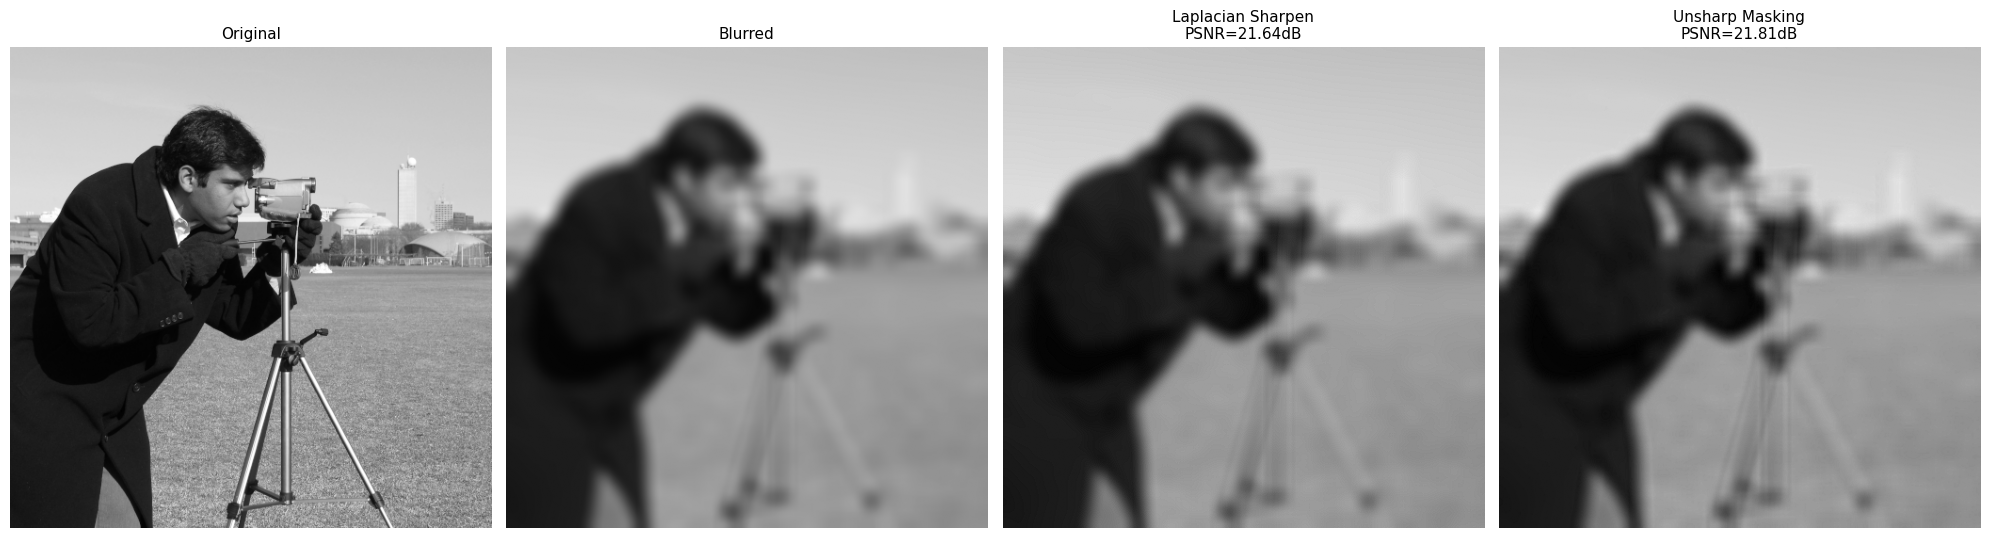

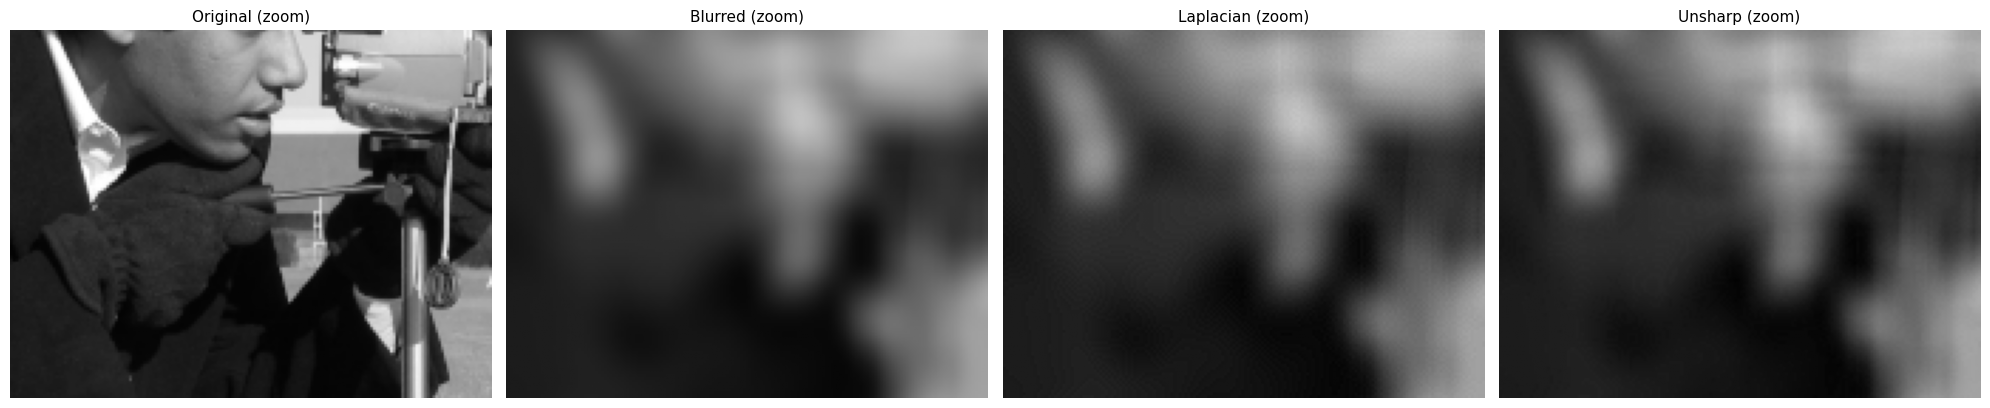

In [ ]:
laplacian_kernel = np.array([[0, 1, 0],
                              [1, -4, 1],
                              [0, 1, 0]])
lap = cv2.filter2D(blurred, cv2.CV_64F, laplacian_kernel)
sharpened_laplacian = np.clip(blurred - lap, 0, 255).astype(np.uint8)

gaussian_smooth = cv2.GaussianBlur(blurred, (9, 9), sigmaX=3)
detail = cv2.subtract(blurred.astype(np.int16), gaussian_smooth.astype(np.int16))
alpha = 2.0  # diperkuat
unsharp = np.clip(blurred.astype(np.int16) + alpha * detail, 0, 255).astype(np.uint8)

fig, ax = plt.subplots(1, 4, figsize=(20, 6))
titles = ['Original', 'Blurred',
          f'Laplacian Sharpen\nPSNR={psnr(original, sharpened_laplacian):.2f}dB',
          f'Unsharp Masking\nPSNR={psnr(original, unsharp):.2f}dB']
for a, img, title in zip(ax, [original, blurred, sharpened_laplacian, unsharp], titles):
    a.imshow(img, cmap='gray', vmin=0, vmax=255)
    a.set_title(title, fontsize=11)
    a.axis('off')
plt.tight_layout()
plt.show()

# ZOOM CROP — area wajah/kamera untuk lihat detail tajam
y1, y2, x1, x2 = 150, 280, 150, 320
fig, ax = plt.subplots(1, 4, figsize=(20, 6))
for a, img, title in zip(ax, [original, blurred, sharpened_laplacian, unsharp],
                          ['Original (zoom)', 'Blurred (zoom)', 'Laplacian (zoom)', 'Unsharp (zoom)']):
    a.imshow(img[y1:y2, x1:x2], cmap='gray', vmin=0, vmax=255)
    a.set_title(title, fontsize=11)
    a.axis('off')
plt.tight_layout()
plt.show()

### A2. Denoising Salt & Pepper Noise — Mean vs Median Filter

Mean filter menghaluskan seluruh citra termasuk derau (blur), sedangkan median filter efektif menghilangkan *impulsive noise* tanpa mengaburkan bagian citra lainnya.

Mean filter (normalisasi kernel):
$$g(m,n) = \frac{\sum_i \sum_j w(i,j) f(m-i,n-j)}{\sum_i \sum_j w(i,j)}$$

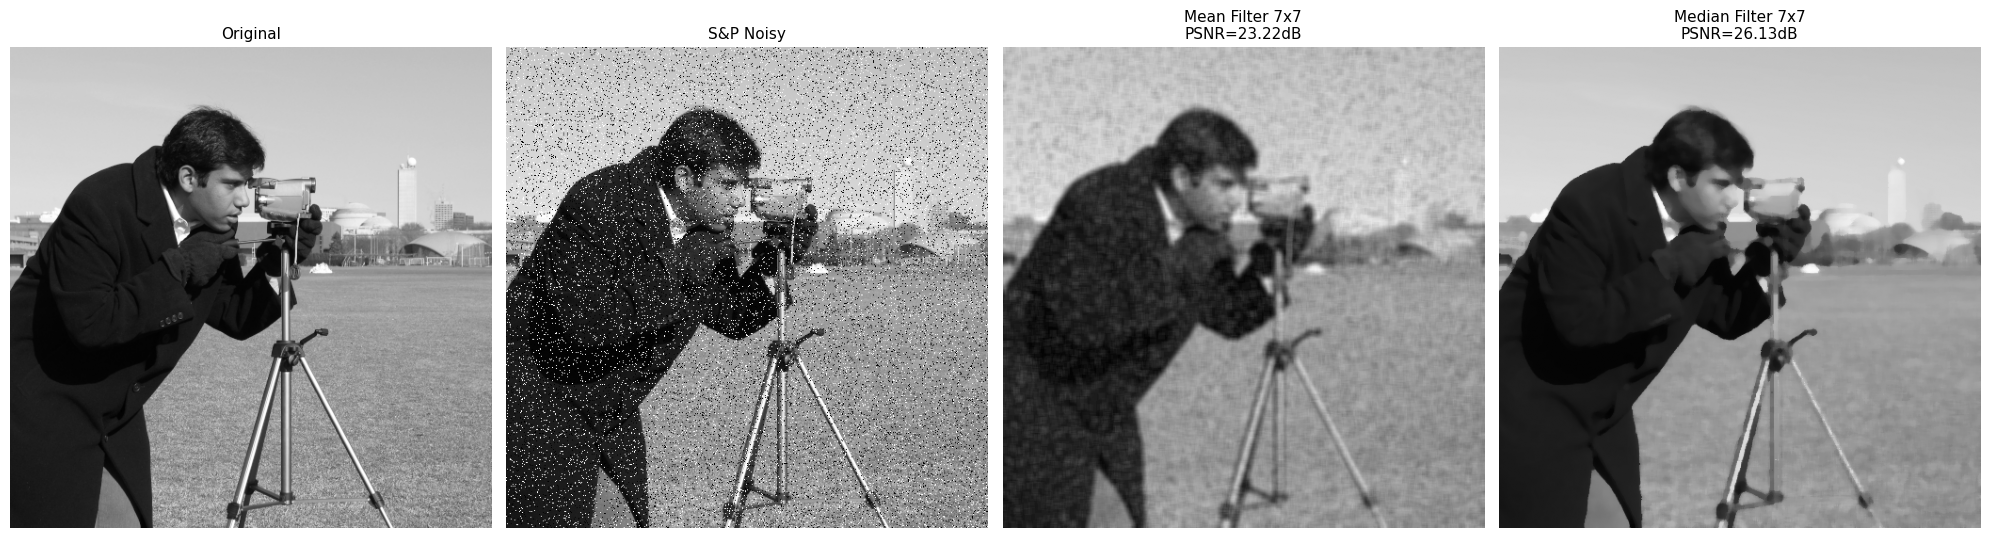

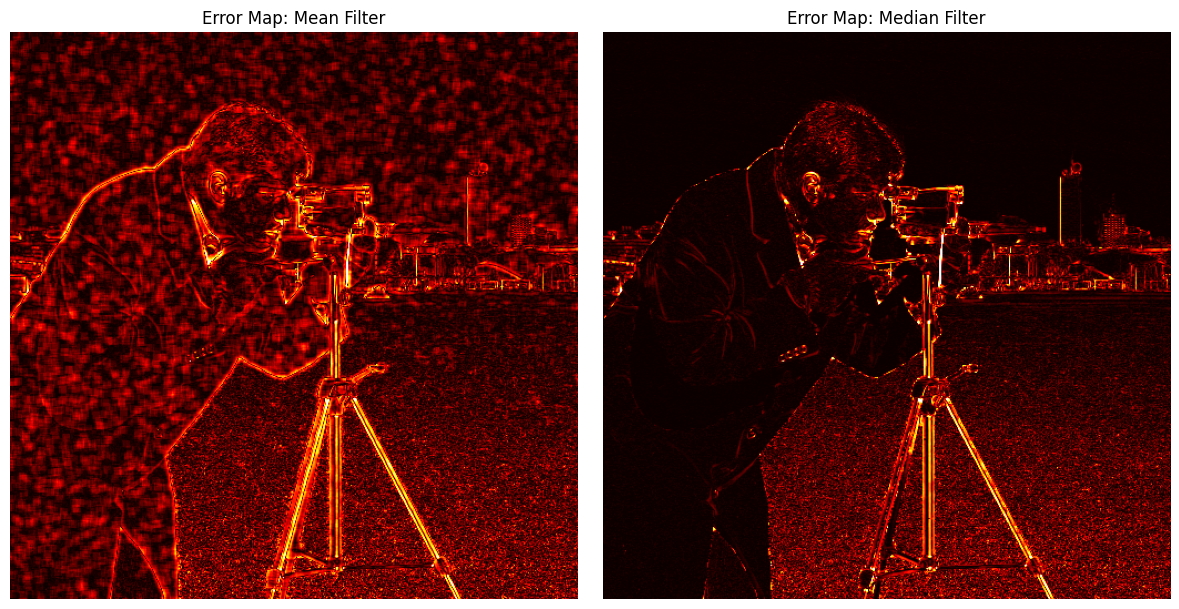

In [ ]:
mean_sp = cv2.blur(sp_noisy, (7, 7))
median_sp = cv2.medianBlur(sp_noisy, 7)

fig, ax = plt.subplots(1, 4, figsize=(20, 6))
titles = ['Original', 'S&P Noisy',
          f'Mean Filter 7x7\nPSNR={psnr(original, mean_sp):.2f}dB',
          f'Median Filter 7x7\nPSNR={psnr(original, median_sp):.2f}dB']
for a, img, title in zip(ax, [original, sp_noisy, mean_sp, median_sp], titles):
    a.imshow(img, cmap='gray', vmin=0, vmax=255)
    a.set_title(title, fontsize=11)
    a.axis('off')
plt.tight_layout()
plt.show()

# difference map terhadap original — makin gelap makin dekat ke original
diff_mean = np.abs(original.astype(int) - mean_sp.astype(int))
diff_median = np.abs(original.astype(int) - median_sp.astype(int))

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(diff_mean, cmap='hot', vmin=0, vmax=100)
ax[0].set_title('Error Map: Mean Filter'); ax[0].axis('off')
ax[1].imshow(diff_median, cmap='hot', vmin=0, vmax=100)
ax[1].set_title('Error Map: Median Filter'); ax[1].axis('off')
plt.tight_layout()
plt.show()

### A3. Denoising Gaussian Noise — Mean vs Gaussian Filter

Gaussian kernel (slide "Gaussian Kernel"):
$$G_\sigma(x,y) = \frac{1}{2\pi\sigma^2} e^{-\frac{x^2+y^2}{2\sigma^2}}$$

Membandingkan beberapa nilai $\sigma$ (sesuai slide "Gaussian filters": $\sigma = 1, 5, 10$).

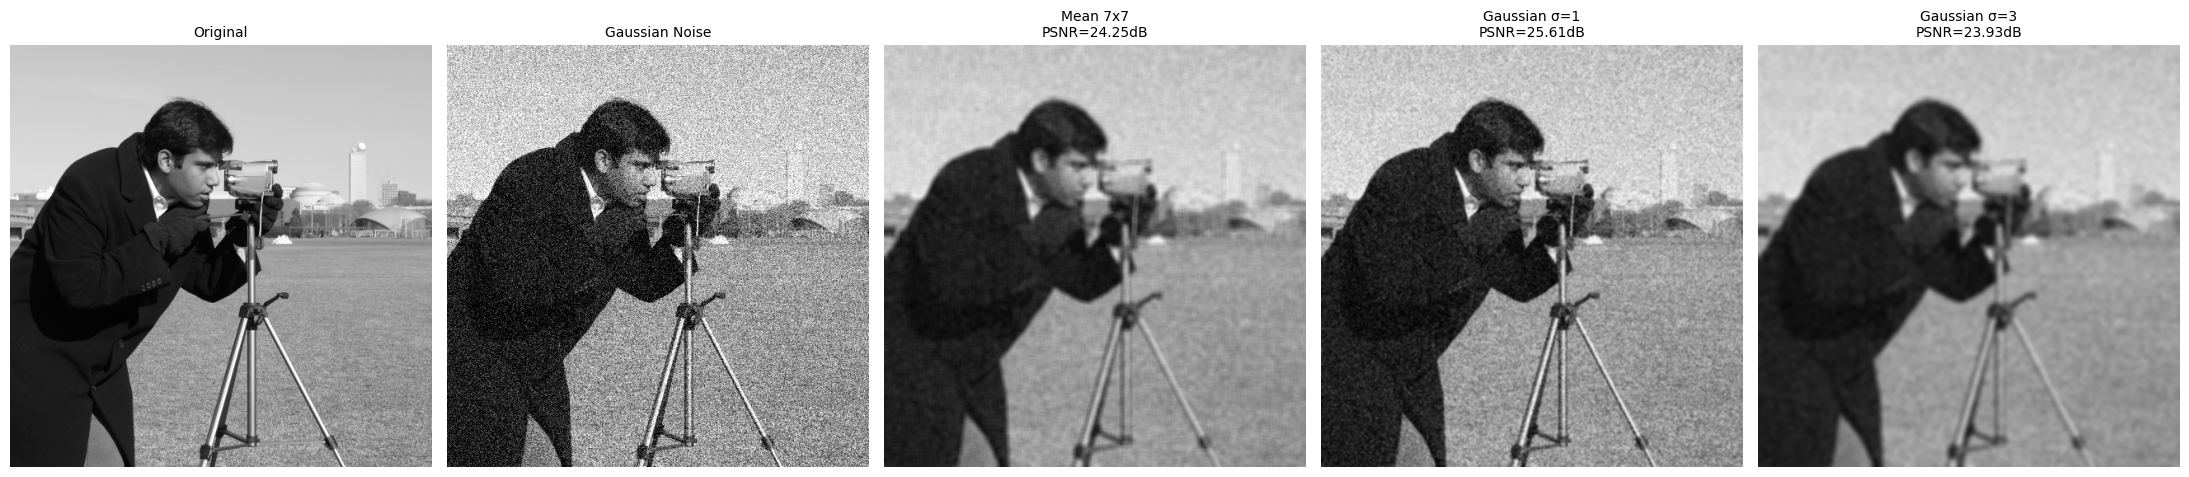

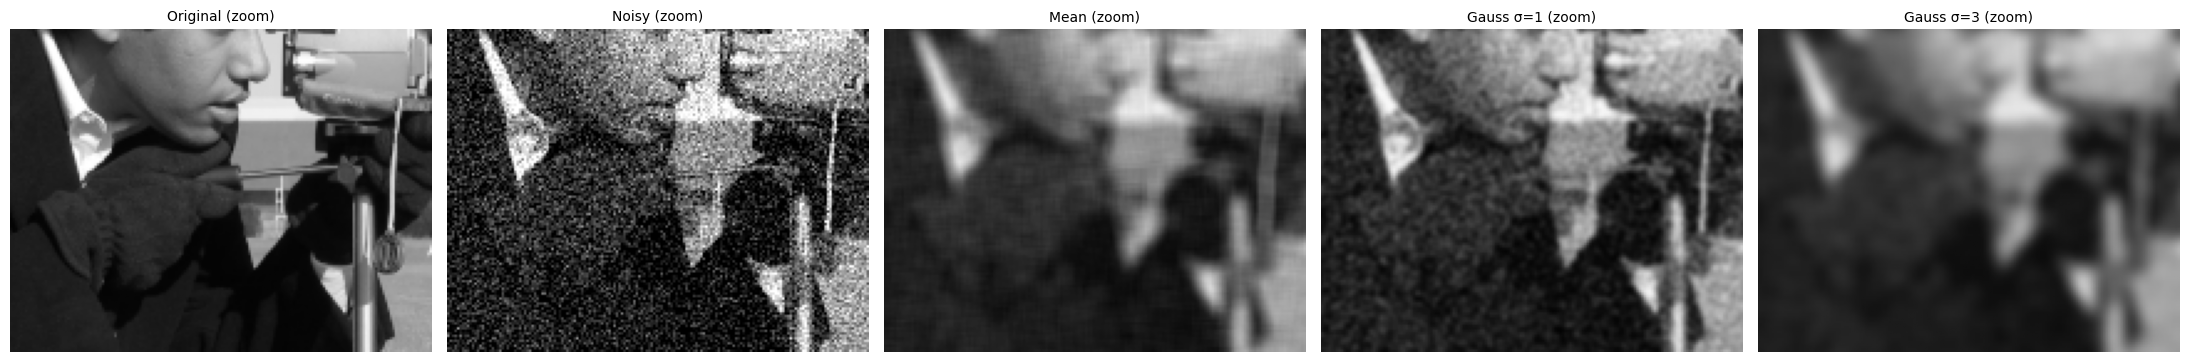

In [ ]:
mean_gn = cv2.blur(gauss_noisy, (7, 7))
gauss_gn_s1 = cv2.GaussianBlur(gauss_noisy, (5, 5), sigmaX=1)
gauss_gn_s3 = cv2.GaussianBlur(gauss_noisy, (11, 11), sigmaX=3)

fig, ax = plt.subplots(1, 5, figsize=(22, 6))
titles = ['Original', 'Gaussian Noise',
          f'Mean 7x7\nPSNR={psnr(original, mean_gn):.2f}dB',
          f'Gaussian σ=1\nPSNR={psnr(original, gauss_gn_s1):.2f}dB',
          f'Gaussian σ=3\nPSNR={psnr(original, gauss_gn_s3):.2f}dB']
for a, img, title in zip(ax, [original, gauss_noisy, mean_gn, gauss_gn_s1, gauss_gn_s3], titles):
    a.imshow(img, cmap='gray', vmin=0, vmax=255)
    a.set_title(title, fontsize=10)
    a.axis('off')
plt.tight_layout()
plt.show()

# zoom crop
fig, ax = plt.subplots(1, 5, figsize=(22, 6))
for a, img, title in zip(ax, [original, gauss_noisy, mean_gn, gauss_gn_s1, gauss_gn_s3],
                          ['Original', 'Noisy', 'Mean', 'Gauss σ=1', 'Gauss σ=3']):
    a.imshow(img[y1:y2, x1:x2], cmap='gray', vmin=0, vmax=255)
    a.set_title(title + ' (zoom)', fontsize=10)
    a.axis('off')
plt.tight_layout()
plt.show()

## SECTION B — Frequency Domain Filtering

### B1. DFT dan Magnitude Spectrum

Basic steps:
1. Kalikan $f(x,y)$ dengan $(-1)^{x+y}$ untuk *centering*
2. Hitung $F(u,v)$ (DFT)
3. $G(u,v) = F(u,v) \cdot H(u,v)$
4. Inverse DFT → $g_1(x,y)$
5. $g(x,y) = g_1(x,y) \cdot (-1)^{x+y}$

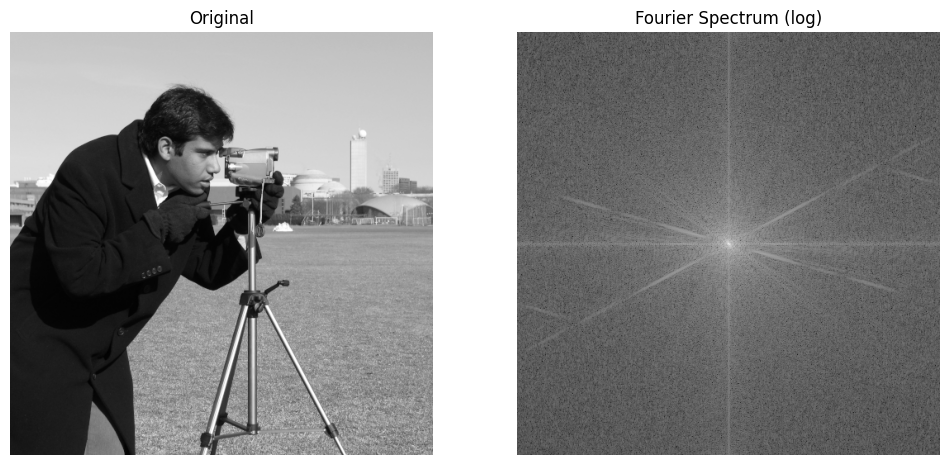

In [ ]:
def get_dft(img):
    dft = np.fft.fft2(img)
    dft_shift = np.fft.fftshift(dft)
    magnitude = 20 * np.log(np.abs(dft_shift) + 1)
    return dft_shift, magnitude

dft_shift, magnitude = get_dft(original)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(original, cmap='gray'); ax[0].set_title('Original'); ax[0].axis('off')
ax[1].imshow(magnitude, cmap='gray'); ax[1].set_title('Fourier Spectrum (log)'); ax[1].axis('off')
plt.show()

### B2. Filter Frequency Domain: Ideal, Butterworth, Gaussian (Low-Pass & High-Pass)

**Ideal LPF/HPF:**
$$H_{LP}(u,v) = \begin{cases} 1 & D(u,v)\le D_0 \\ 0 & D(u,v) > D_0 \end{cases}, \quad H_{HP} = 1 - H_{LP}$$

**Butterworth LPF/HPF (order $n$):**
$$H_{LP}(u,v) = \frac{1}{1+[D(u,v)/D_0]^{2n}}, \quad H_{HP}(u,v) = \frac{1}{1+[D_0/D(u,v)]^{2n}}$$

**Gaussian LPF/HPF:**
$$H_{LP}(u,v) = e^{-D(u,v)^2/2D_0^2}, \quad H_{HP}(u,v) = 1 - H_{LP}(u,v)$$

dengan $D(u,v)$ = jarak titik $(u,v)$ ke pusat spektrum.

In [ ]:
def distance_matrix(shape):
    P, Q = shape
    u = np.arange(P) - P // 2
    v = np.arange(Q) - Q // 2
    V, U = np.meshgrid(v, u)
    D = np.sqrt(U**2 + V**2)
    return D

def ideal_filter(shape, D0, highpass=False):
    D = distance_matrix(shape)
    H = (D <= D0).astype(float)
    return 1 - H if highpass else H

def butterworth_filter(shape, D0, n=2, highpass=False):
    D = distance_matrix(shape)
    D[D == 0] = 1e-6
    if highpass:
        H = 1 / (1 + (D0 / D) ** (2 * n))
    else:
        H = 1 / (1 + (D / D0) ** (2 * n))
    return H

def gaussian_filter_freq(shape, D0, highpass=False):
    D = distance_matrix(shape)
    H = np.exp(-(D ** 2) / (2 * (D0 ** 2)))
    return 1 - H if highpass else H

def apply_freq_filter(img, H):
    dft = np.fft.fft2(img)
    dft_shift = np.fft.fftshift(dft)
    filtered_shift = dft_shift * H
    filtered = np.fft.ifft2(np.fft.ifftshift(filtered_shift))
    filtered = np.abs(filtered)
    return np.clip(filtered, 0, 255).astype(np.uint8)

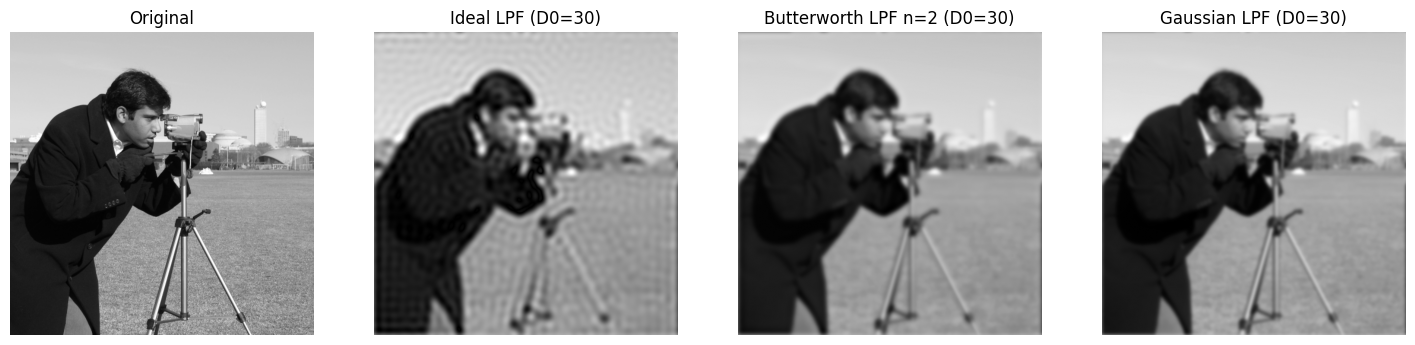

In [ ]:
D0 = 30
H_ideal_lp = ideal_filter(original.shape, D0)
H_butter_lp = butterworth_filter(original.shape, D0, n=2)
H_gauss_lp = gaussian_filter_freq(original.shape, D0)

res_ideal_lp = apply_freq_filter(original, H_ideal_lp)
res_butter_lp = apply_freq_filter(original, H_butter_lp)
res_gauss_lp = apply_freq_filter(original, H_gauss_lp)

fig, ax = plt.subplots(1, 4, figsize=(18, 5))
for a, img, title in zip(
    ax, [original, res_ideal_lp, res_butter_lp, res_gauss_lp],
    ['Original', f'Ideal LPF (D0={D0})', f'Butterworth LPF n=2 (D0={D0})', f'Gaussian LPF (D0={D0})']
):
    a.imshow(img, cmap='gray')
    a.set_title(title)
    a.axis('off')
plt.show()

Ideal filter memiliki transisi tajam pada domain frekuensi, sehingga menimbulkan efek **ringing** pada domain spasial. Butterworth dan Gaussian memiliki transisi halus sehingga hasil lebih natural.

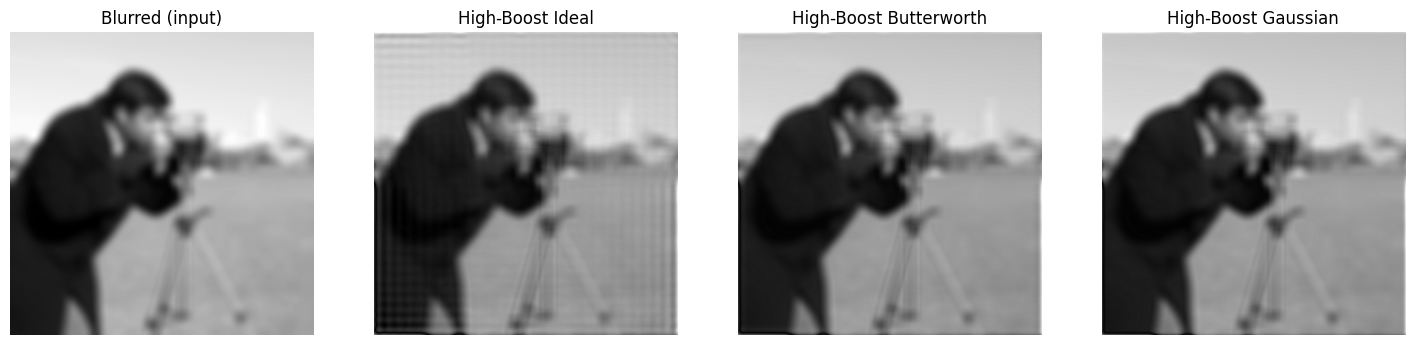

PSNR Blurred             : 21.61 dB
PSNR High-Boost Ideal     : 21.21 dB
PSNR High-Boost Butterworth: 21.45 dB
PSNR High-Boost Gaussian  : 21.58 dB


In [ ]:
D0_hp = 30
H_ideal_hp = ideal_filter(original.shape, D0_hp, highpass=True)
H_butter_hp = butterworth_filter(original.shape, D0_hp, n=2, highpass=True)
H_gauss_hp = gaussian_filter_freq(original.shape, D0_hp, highpass=True)

res_ideal_hp = apply_freq_filter(blurred, H_ideal_hp)
res_butter_hp = apply_freq_filter(blurred, H_butter_hp)
res_gauss_hp = apply_freq_filter(blurred, H_gauss_hp)

def high_boost(img, H, k=1.5):
    dft = np.fft.fft2(img)
    dft_shift = np.fft.fftshift(dft)
    boosted_H = 1 + k * H
    result_shift = dft_shift * boosted_H
    result = np.abs(np.fft.ifft2(np.fft.ifftshift(result_shift)))
    return np.clip(result, 0, 255).astype(np.uint8)

hb_ideal = high_boost(blurred, H_ideal_hp)
hb_butter = high_boost(blurred, H_butter_hp)
hb_gauss = high_boost(blurred, H_gauss_hp)

fig, ax = plt.subplots(1, 4, figsize=(18, 5))
for a, img, title in zip(
    ax, [blurred, hb_ideal, hb_butter, hb_gauss],
    ['Blurred (input)', 'High-Boost Ideal', 'High-Boost Butterworth', 'High-Boost Gaussian']
):
    a.imshow(img, cmap='gray')
    a.set_title(title)
    a.axis('off')
plt.show()

print(f"PSNR Blurred             : {psnr(original, blurred):.2f} dB")
print(f"PSNR High-Boost Ideal     : {psnr(original, hb_ideal):.2f} dB")
print(f"PSNR High-Boost Butterworth: {psnr(original, hb_butter):.2f} dB")
print(f"PSNR High-Boost Gaussian  : {psnr(original, hb_gauss):.2f} dB")

### B3. Perbandingan Sharpening: Spatial Domain vs Frequency Domain



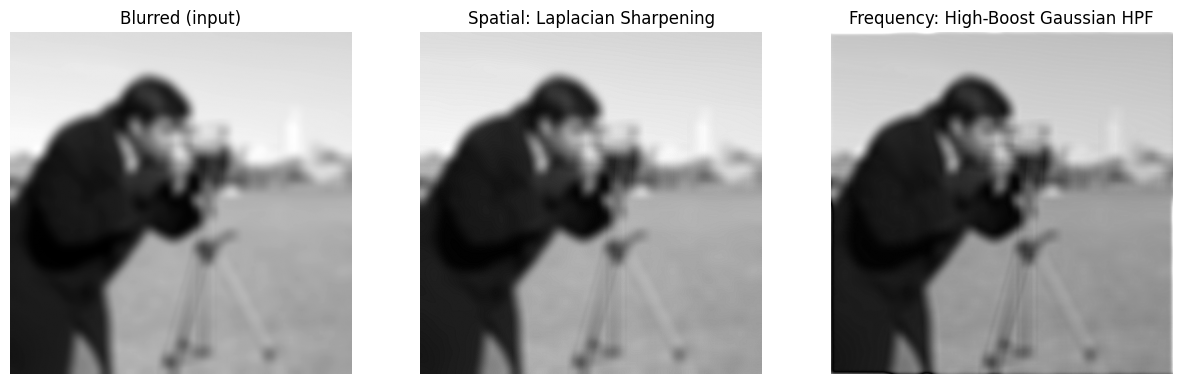

PSNR Laplacian Sharpening (spatial)  : 21.64 dB
PSNR High-Boost Gaussian (frequency) : 21.58 dB


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, img, title in zip(
    ax, [blurred, sharpened_laplacian, hb_gauss],
    ['Blurred (input)', 'Spatial: Laplacian Sharpening', 'Frequency: High-Boost Gaussian HPF']
):
    a.imshow(img, cmap='gray')
    a.set_title(title)
    a.axis('off')
plt.show()

print(f"PSNR Laplacian Sharpening (spatial)  : {psnr(original, sharpened_laplacian):.2f} dB")
print(f"PSNR High-Boost Gaussian (frequency) : {psnr(original, hb_gauss):.2f} dB")

## SECTION C — Ringkasan Evaluasi Kuantitatif (MSE & PSNR)

In [ ]:
import pandas as pd

results = {
    'Metode': [
        'Blurred (no enhancement)', 'Laplacian Sharpening', 'Unsharp Masking',
        'High-Boost Ideal HPF', 'High-Boost Butterworth HPF', 'High-Boost Gaussian HPF',
        'Salt&Pepper Noisy', 'Mean Filter (S&P)', 'Median Filter (S&P)',
        'Gaussian Noisy', 'Mean Filter (Gauss noise)', 'Gaussian Filter σ=1', 'Gaussian Filter σ=3'
    ],
    'MSE': [
        mse(original, blurred), mse(original, sharpened_laplacian), mse(original, unsharp),
        mse(original, hb_ideal), mse(original, hb_butter), mse(original, hb_gauss),
        mse(original, sp_noisy), mse(original, mean_sp), mse(original, median_sp),
        mse(original, gauss_noisy), mse(original, mean_gn), mse(original, gauss_gn_s1), mse(original, gauss_gn_s3)
    ],
    'PSNR (dB)': [
        psnr(original, blurred), psnr(original, sharpened_laplacian), psnr(original, unsharp),
        psnr(original, hb_ideal), psnr(original, hb_butter), psnr(original, hb_gauss),
        psnr(original, sp_noisy), psnr(original, mean_sp), psnr(original, median_sp),
        psnr(original, gauss_noisy), psnr(original, mean_gn), psnr(original, gauss_gn_s1), psnr(original, gauss_gn_s3)
    ]
}

df = pd.DataFrame(results)
df

,Metode,MSE,PSNR (dB)
0,Blurred (no enhancement),449.017975,21.608166
1,Laplacian Sharpening,446.033829,21.637126
2,Unsharp Masking,428.251831,21.813811
3,High-Boost Ideal HPF,491.770035,21.213183
4,High-Boost Butterworth HPF,465.598732,21.450686
5,High-Boost Gaussian HPF,451.821564,21.581134
6,Salt&Pepper Noisy,2168.449280,14.769311
7,Mean Filter (S&P),309.679142,23.221684
8,Median Filter (S&P),158.451241,26.131847
9,Gaussian Noisy,1106.624779,17.690800
